# For Computing posterior we run an algorithm called Monte Carlo Markov Chain (MCMC).
## * It samples from the posterior
## * In the near future we will learn about it more.
## * First, let's see how we use it in code.

## * We write our code button to up



In [ ]:
import pymc as pm
import matplotlib.pyplot as plt

n_trials = 10
succses = 8
with pm.Model() as baseball: # With statement: all code indented here, belongs to
                          # the "model", which is the name of the Bayesian model

    # Part 3: Priors
    ## Here we have only one prior
    ## We define a distirbution without "observed" like in the likelihood
    ## The parameters should represent at least one of the likelihood parameters.
    theta = pm.Beta('Theta', alpha=81, beta=219)

    # Part 2: Likelihood
    ## We first choose the likelihood distribution
    ## We give it a name which can be seen the model graph
    ## Each distirbution has its own parameters
    ## In binomial case we have "n" and "p"
    ## We have the var: observed. This what makes it a likelihood fucntion
    hits = pm.Binomial('hits',n=n_trials, p=theta, observed=succses)


    # Part 1: sampling the mcmc.
    ## We always start with pm.sample
    ## We then indicate the number of samples
    ## The number of tune reflects how many examples are burn-in.
    ## Cores - the number of CPU cores that run simoultansly.
    ## Depeneds how strong your computer
    ## Chain - how many chains we run simoultansly.
    baseball_samples = pm.sample(5000, tune=1000, cores= 1, chains = 4)

Output()

# Creating a model Graph
## White ovals refer to prios
## Gray ovals refer to likelihood

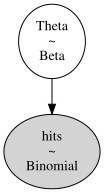

In [ ]:
pm.model_to_graphviz(baseball)

# Discrete Distributions

In [ ]:
pm.Bernoulli(p)
# p: float – Probability of success (0 ≤ p ≤ 1)

pm.Binomial(n, p)
# n: int – Number of trials
# p: float – Probability of success per trial (0 ≤ p ≤ 1)

pm.Poisson(mu)
# mu: float – Expected number of occurrences (rate parameter)

pm.Geometric(p)
# p: float – Probability of success (0 ≤ p ≤ 1)

pm.Categorical(p)
# p: array-like – Probabilities for each category (sum must be 1)

pm.DiscreteUniform(lower, upper)
# lower: int – Lower bound
# upper: int – Upper bound

# Continous Distributions

In [ ]:
pm.Normal(mu, sigma)
# mu: float – Mean
# sigma: float – Standard deviation (σ > 0)

pm.Uniform(lower, upper)
# lower: float – Lower bound
# upper: float – Upper bound

pm.Exponential(lam)
# lam: float – Rate parameter (λ > 0)

pm.Lognormal(mu, sigma)
# mu: float – Mean
# sigma: float – Standard deviation (σ > 0)

pm.StudentT(nu, mu, sigma)
# nu: float – Degrees of freedom (ν > 0)
# mu: float – Location parameter
# sigma: float – Scale parameter (σ > 0)

pm.Weibull(alpha, beta)
# alpha: float – Shape parameter (α > 0)
# beta: float – Scale parameter (β > 0)

## Extracting the posterior values from MCMC
### The posterior is on the baseball_samples variable.
### The posterior is extraced by: baseball_samples.posterior['theta']
### 'theta' is how we named it parameter in the model.


In [ ]:
baseball_samples.posterior['Theta'].shape

(4, 5000)

In [ ]:
np.array(baseball_samples.posterior['Theta']).flatten().shape

(20000,)

## Creating an histogram of theta

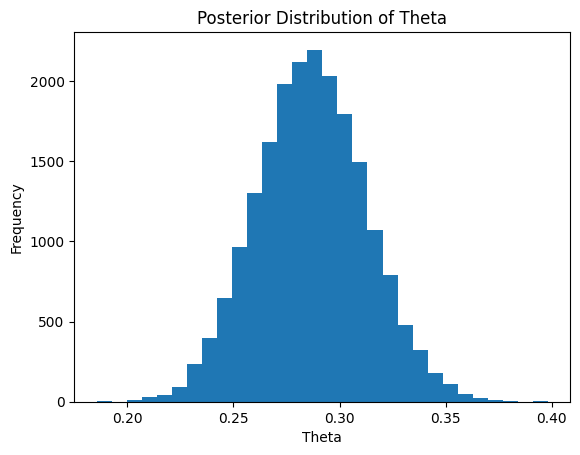

In [ ]:
# Ceating an histrogram from the var baseball_samples which is the pymc posterior

import matplotlib.pyplot as plt

plt.hist(np.array(baseball_samples.posterior['Theta']).flatten(), bins=30)
plt.xlabel("Theta")
plt.ylabel("Frequency")
plt.title("Posterior Distribution of Theta")
plt.show()
